# Exploratory Data Analysis (EDA) on Payment Failure Dataset

## 1. Load dataset

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming the notebook is saved in ml/notebooks/
# We use '../data/' to go up one directory and into the data folder
file_path = '../data/payment_failure_dataset.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2. First 5 rows

In [13]:
# Display the first 5 rows to verify the data loaded correctly
df.head()

,payment_id,customer_id,amount,payment_method,retry_count,transactions_last_24h,time_since_last_payment_min,hour_of_day,day_of_week,subscription_status,customer_tenure_days,previous_payment_count,previous_failure_count,historical_success_rate,payment_failed
0,PAY_000001,CUST_07271,98.27,CARD,0,0,279.0,15,1,active,81,111,5,0.9550,0
1,PAY_000002,CUST_00861,263.43,UPI,1,1,921.0,8,2,active,119,25,1,0.9600,1
2,PAY_000003,CUST_05391,428.18,UPI,0,2,635.0,1,1,active,304,101,0,1.0000,0
3,PAY_000004,CUST_05192,284.38,UPI,0,0,111.0,5,3,active,1122,95,2,0.9789,0
4,PAY_000005,CUST_05735,99.89,UPI,0,2,1976.0,6,2,active,836,75,4,0.9467,0


## 3. Dataset shape

In [14]:
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

Total Rows: 50000
Total Columns: 15


## 4. Column names and data types

In [15]:
# This will show us which columns are numbers (int64/float64) and which are text (object)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   payment_id                   50000 non-null  str    
 1   customer_id                  50000 non-null  str    
 2   amount                       50000 non-null  float64
 3   payment_method               50000 non-null  str    
 4   retry_count                  50000 non-null  int64  
 5   transactions_last_24h        50000 non-null  int64  
 6   time_since_last_payment_min  50000 non-null  float64
 7   hour_of_day                  50000 non-null  int64  
 8   day_of_week                  50000 non-null  int64  
 9   subscription_status          50000 non-null  str    
 10  customer_tenure_days         50000 non-null  int64  
 11  previous_payment_count       50000 non-null  int64  
 12  previous_failure_count       50000 non-null  int64  
 13  historical_success_rate    

## 5. Missing values
## 6. Duplicate payment IDs
## 7. Duplicate rows

In [16]:
print("--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Payment IDs ---")
print(df['payment_id'].duplicated().sum())

print("\n--- Duplicate Rows ---")
print(df.duplicated().sum())

--- Missing Values ---
payment_id                     0
customer_id                    0
amount                         0
payment_method                 0
retry_count                    0
transactions_last_24h          0
time_since_last_payment_min    0
hour_of_day                    0
day_of_week                    0
subscription_status            0
customer_tenure_days           0
previous_payment_count         0
previous_failure_count         0
historical_success_rate        0
payment_failed                 0
dtype: int64

--- Duplicate Payment IDs ---
0

--- Duplicate Rows ---
0


## 8. Descriptive statistics

In [17]:
# Summary statistics for all numerical columns
df.describe().round(2)

,amount,retry_count,transactions_last_24h,time_since_last_payment_min,hour_of_day,day_of_week,customer_tenure_days,previous_payment_count,previous_failure_count,historical_success_rate,payment_failed
count,50000.00,50000.00,50000.0,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,404.59,0.21,1.2,1438.85,11.49,3.00,918.46,60.04,2.97,0.95,0.19
std,513.50,0.55,1.1,1434.87,6.92,1.99,509.19,34.13,2.37,0.05,0.39
min,2.81,0.00,0.0,0.00,0.00,0.00,30.00,1.00,0.00,0.00,0.00
25%,124.68,0.00,0.0,414.00,5.00,1.00,483.00,30.00,1.00,0.93,0.00
50%,246.38,0.00,1.0,996.00,11.00,3.00,922.00,60.00,3.00,0.95,0.00
75%,483.80,0.00,2.0,1994.00,18.00,5.00,1356.00,89.00,4.00,0.98,0.00
max,10510.76,3.00,7.0,17468.00,23.00,6.00,1799.00,119.00,14.00,1.00,1.00


## 9. Target distribution
Checking the counts and percentages of successful payments (0) vs. failed payments (1).

In [18]:
target_counts = df['payment_failed'].value_counts()
target_pct = df['payment_failed'].value_counts(normalize=True) * 100

print("Target Counts:")
print(target_counts)

print("\nTarget Percentages (%):")
print(target_pct.round(2))

Target Counts:
payment_failed
0    40648
1     9352
Name: count, dtype: int64

Target Percentages (%):
payment_failed
0    81.3
1    18.7
Name: proportion, dtype: float64


## 10. Failure rate by payment method
## 11. Failure rate by retry count
## 12. Failure rate by subscription status

By calculating the mean of the `payment_failed` column (which contains only 0s and 1s), we get the exact failure probability for each category.

In [19]:
print("--- Failure Rate by Payment Method (%) ---")
print((df.groupby('payment_method')['payment_failed'].mean() * 100).round(2))

print("\n--- Failure Rate by Retry Count (%) ---")
print((df.groupby('retry_count')['payment_failed'].mean() * 100).round(2))

print("\n--- Failure Rate by Subscription Status (%) ---")
print((df.groupby('subscription_status')['payment_failed'].mean() * 100).round(2))

--- Failure Rate by Payment Method (%) ---
payment_method
CARD          20.84
NETBANKING    22.28
UPI           17.28
WALLET        14.30
Name: payment_failed, dtype: float64

--- Failure Rate by Retry Count (%) ---
retry_count
0    13.37
1    36.52
2    68.98
3    90.61
Name: payment_failed, dtype: float64

--- Failure Rate by Subscription Status (%) ---
subscription_status
active       15.99
cancelled    60.14
paused       38.89
Name: payment_failed, dtype: float64


## 13. Failure rate by historical success rate
## 14. Failure rate by amount ranges

Because success rate and amount are continuous numbers, we will group them into "bins" (ranges) to see how the failure rate changes across different levels.

In [20]:
# Create temporary bins for historical success rate
df['success_rate_bin'] = pd.cut(df['historical_success_rate'], bins=[0.0, 0.5, 0.8, 0.9, 0.95, 1.0])
print("--- Failure Rate by Historical Success Rate Bins (%) ---")
print((df.groupby('success_rate_bin', observed=False)['payment_failed'].mean() * 100).round(2))

# Create temporary bins for transaction amount
df['amount_bin'] = pd.cut(df['amount'], bins=[0, 50, 250, 1000, 5000])
print("\n--- Failure Rate by Amount Ranges (%) ---")
print((df.groupby('amount_bin', observed=False)['payment_failed'].mean() * 100).round(2))

--- Failure Rate by Historical Success Rate Bins (%) ---
success_rate_bin
(0.0, 0.5]     66.67
(0.5, 0.8]     32.90
(0.8, 0.9]     23.27
(0.9, 0.95]    19.97
(0.95, 1.0]    16.86
Name: payment_failed, dtype: float64

--- Failure Rate by Amount Ranges (%) ---
amount_bin
(0, 50]         16.21
(50, 250]       18.19
(250, 1000]     19.27
(1000, 5000]    20.42
Name: payment_failed, dtype: float64


## 15. Failure rate by hour
## 16. Failure rate by transactions_last_24h

In [21]:
print("--- Failure Rate by Hour of Day (%) ---")
print((df.groupby('hour_of_day')['payment_failed'].mean() * 100).round(2))

print("\n--- Failure Rate by Transactions in Last 24h (%) ---")
print((df.groupby('transactions_last_24h')['payment_failed'].mean() * 100).round(2))

--- Failure Rate by Hour of Day (%) ---
hour_of_day
0     27.95
1     28.12
2     28.19
3     27.47
4     24.89
5     15.61
6     17.03
7     17.21
8     15.46
9     16.13
10    15.13
11    15.62
12    17.12
13    15.53
14    15.50
15    17.50
16    16.41
17    16.77
18    17.84
19    16.95
20    15.91
21    17.40
22    16.94
23    15.98
Name: payment_failed, dtype: float64

--- Failure Rate by Transactions in Last 24h (%) ---
transactions_last_24h
0    16.68
1    16.63
2    16.77
3    32.61
4    35.47
5    35.14
6    34.33
7    25.00
Name: payment_failed, dtype: float64


## 17. Useful visualizations
Let's visualize the target distribution and the relationships between failure rate and our categorical features. Seaborn's `barplot` automatically calculates the mean (failure rate) for the y-axis.

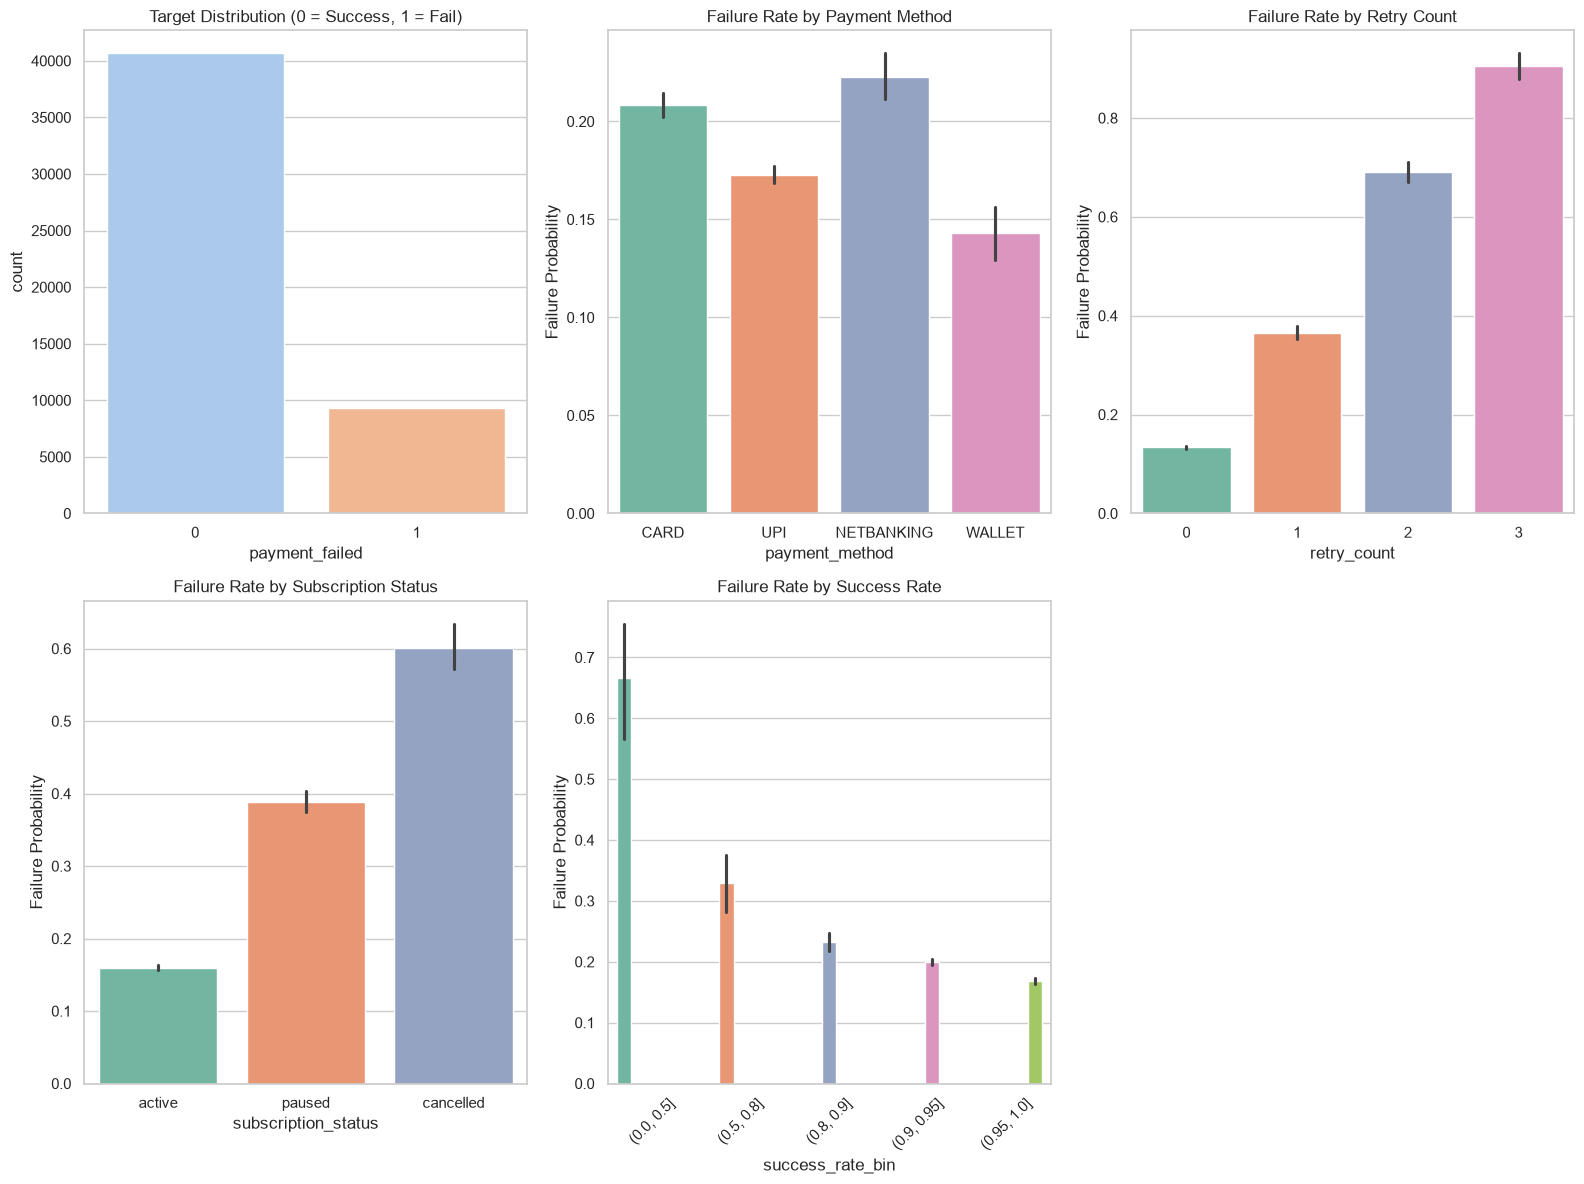

In [22]:
# Set the visual style for the charts
sns.set_theme(style="whitegrid")

# Create a figure holding multiple subplots
plt.figure(figsize=(16, 12))

# 1. Target Distribution
plt.subplot(2, 3, 1)
sns.countplot(data=df, x='payment_failed', palette='pastel', hue='payment_failed', legend=False)
plt.title('Target Distribution (0 = Success, 1 = Fail)')

# 2. Failure Rate by Payment Method
plt.subplot(2, 3, 2)
sns.barplot(data=df, x='payment_method', y='payment_failed', palette='Set2', hue='payment_method', legend=False)
plt.title('Failure Rate by Payment Method')
plt.ylabel('Failure Probability')

# 3. Failure Rate by Retry Count
plt.subplot(2, 3, 3)
sns.barplot(data=df, x='retry_count', y='payment_failed', palette='Set2', hue='retry_count', legend=False)
plt.title('Failure Rate by Retry Count')
plt.ylabel('Failure Probability')

# 4. Failure Rate by Subscription Status
plt.subplot(2, 3, 4)
sns.barplot(data=df, x='subscription_status', y='payment_failed', palette='Set2', hue='subscription_status', legend=False)
plt.title('Failure Rate by Subscription Status')
plt.ylabel('Failure Probability')

# 5. Failure Rate by Historical Success Rate Bins
plt.subplot(2, 3, 5)
sns.barplot(data=df, x='success_rate_bin', y='payment_failed', palette='Set2', hue='success_rate_bin', legend=False)
plt.title('Failure Rate by Success Rate')
plt.xticks(rotation=45) # Rotate labels so they don't overlap
plt.ylabel('Failure Probability')

# Clean up layout and display
plt.tight_layout()
plt.show()